# Ablation Studies

1. **OVOD ensemble at different confidence thresholds** — precision/recall/F1 of
   Grounding DINO alone vs. ensembles with YOLO-World and OWL-ViT, swept over
   calibrated-score thresholds 0.1–0.5.
2. **AP / AS ablation table** — best-achievable AP and AS (`AS_strict` in code) of
   PLS, GKR and kNN at 1%, 10% and 100% annotation budget on all four datasets
   (COCO, Cityscapes, KITTI, Pascal VOC), from the grid-search results also used
   by `annotation_benchmark_results.ipynb`.
3. **CLIP-embedding graph vs. GDino-embedding graph** — PLS's similarity graph built
   from CLIP image-crop embeddings instead of GDino decoder embeddings, alone and
   combined in a Bayesian objectness blend, at 1%/10%/100% budget on COCO val.

# 1 OVOD Ensemble — F1 at Lower Confidence Thresholds

Setup: SoftTeacher's COCO train split fold 1 with 1% labeled images, which serve both
for calibration and evaluation. Each detector (Grounding DINO, OWL-ViT, YOLO-World) is
Platt-scaled on these images, detections of the ensemble members are pooled and
reduced by class-aware NMS (IoU 0.5) in which Grounding DINO detections take priority
over the other models' detections regardless of score, and survivors are matched to
GT (IoU ≥ 0.5, same class, score-descending greedy).

NMS survival does not depend on the score threshold, so NMS and TP matching run once
per configuration and only the final keep/discard step is re-evaluated per threshold.

In [1]:
import os
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# calibration/ and inference/ are top-level packages of the repo
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

st_dir = "/home/klees/SoftTeacher/"
fold, perc_labeled = 1, 1   # SoftTeacher semi-supervised split: fold 1, 1% labeled

labels_json = os.path.join(st_dir, f"data/coco/annotations/semi_supervised/instances_train2017.{fold}@{perc_labeled}.json")
with open(labels_json) as f:
    ovod_labels = json.load(f)
ovod_image_ids = [img["id"] for img in ovod_labels["images"]]
print(f"Fold {fold}, {perc_labeled}% budget: {len(ovod_image_ids)} labeled images, "
      f"{len(ovod_labels['annotations'])} GT instances")

Fold 1, 1% budget: 1182 labeled images, 8646 GT instances


In [2]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from sklearn.linear_model import LogisticRegression

from calibration.calibrate import gather_detections_from_parquet, extract_per_image_scores, flatten_per_image_data

MODEL_PARQUETS = {
    "gdino":     os.path.join(repo_root, "inference/predictions/gdino/coco_train/predictions.parquet"),
    "owlvit":    os.path.join(repo_root, "inference/predictions/owlvit/coco_train_fold1_1pct/predictions.parquet"),
    "yoloworld": os.path.join(repo_root, "inference/predictions/yolov8l-worldv2/coco_train_fold1_1pct/predictions.parquet"),
}
NMS_IOU_THRESHOLD = 0.5

cocoGt = COCO(labels_json)

# Per-model Platt scaling: logistic regression of TP (IoU >= 0.5) on the raw score
calibrators = {}
for model_name, parquet_path in MODEL_PARQUETS.items():
    print(f"Calibrating {model_name} on {len(ovod_image_ids)} labeled images...")
    all_detections = gather_detections_from_parquet(ovod_image_ids, parquet_path)

    cocoDt = cocoGt.loadRes(all_detections)
    cocoEval = COCOeval(cocoGt, cocoDt, "bbox")
    cocoEval.params.iouThrs = [0.5]
    cocoEval.params.areaRng = [cocoEval.params.areaRng[0]]
    cocoEval.params.maxDets = [300]
    cocoEval.evaluate()
    cocoEval.accumulate()

    per_image = extract_per_image_scores(cocoEval)
    scores, TP_mask, _ = flatten_per_image_data(per_image)

    clf = LogisticRegression()
    clf.fit(scores.reshape(-1, 1), TP_mask)
    calibrators[model_name] = clf

print("Calibrators fit:", list(calibrators.keys()))

loading annotations into memory...
Done (t=0.20s)
creating index...
index created!
Calibrating gdino on 1182 labeled images...


Loading and preparing results...


DONE (t=1.87s)
creating index...


index created!
Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=2.97s).
Accumulating evaluation results...
DONE (t=0.12s).


...

Calibrating yoloworld on 1182 labeled images...


Loading and preparing results...


DONE (t=1.10s)
creating index...
index created!


Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=0.92s).
Accumulating evaluation results...
DONE (t=0.05s).
Calibrators fit: ['gdino', 'owlvit', 'yoloworld']


In [3]:
# Raw (xyxy) detections per model, restricted to the labeled images, calibrated with each
# model's own calibrator and tagged with their source model
per_model_df = {}
for model_name, parquet_path in MODEL_PARQUETS.items():
    df = pd.read_parquet(parquet_path, columns=["image_id", "score", "label", "box"])
    df = df[df["image_id"].isin(set(ovod_image_ids))].copy()
    df["calibrated_score"] = calibrators[model_name].predict_proba(
        df["score"].to_numpy().reshape(-1, 1)
    )[:, 1]
    df["model"] = model_name
    per_model_df[model_name] = df

combined_df   = pd.concat(per_model_df.values(), ignore_index=True)
gdino_only_df = combined_df[combined_df["model"] == "gdino"]
two_model_df  = combined_df[combined_df["model"] != "owlvit"]   # GDINO + YOLO-World, no OWL-ViT

print("Raw detections per model (labeled images only):")
print(combined_df.groupby("model").size())

Raw detections per model (labeled images only):
model
gdino        354600
owlvit       437801
yoloworld    125600
dtype: int64


In [4]:
from tqdm.auto import tqdm

def _iou_matrix(b1, b2):
    """(N,4)x(M,4) -> (N,M) IoU; boxes as [x1,y1,x2,y2]."""
    if len(b1) == 0 or len(b2) == 0:
        return np.zeros((len(b1), len(b2)))
    x1 = np.maximum(b1[:, None, 0], b2[None, :, 0])
    y1 = np.maximum(b1[:, None, 1], b2[None, :, 1])
    x2 = np.minimum(b1[:, None, 2], b2[None, :, 2])
    y2 = np.minimum(b1[:, None, 3], b2[None, :, 3])
    inter  = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    areas1 = (b1[:, 2] - b1[:, 0]) * (b1[:, 3] - b1[:, 1])
    areas2 = (b2[:, 2] - b2[:, 0]) * (b2[:, 3] - b2[:, 1])
    return inter / np.maximum(areas1[:, None] + areas2[None, :] - inter, 1e-6)

def _nms(boxes, scores, cat_ids, iou_thr, class_agnostic, priority_mask=None, priority_bonus=1.0):
    """Boolean survive mask after NMS (per-class or class-agnostic). priority_mask ranks those
    detections above all others (ties still resolve by score); threshold-independent."""
    rank_scores = scores + (priority_bonus * priority_mask if priority_mask is not None else 0.0)
    survive = np.zeros(len(boxes), dtype=bool)
    groups  = [None] if class_agnostic else np.unique(cat_ids)
    for g in groups:
        idx = np.arange(len(boxes)) if g is None else np.where(cat_ids == g)[0]
        if len(idx) == 0:
            continue
        order   = np.argsort(rank_scores[idx])[::-1]
        b_ord   = boxes[idx][order]
        iou_mat = _iou_matrix(b_ord, b_ord)
        sup     = np.zeros(len(idx), dtype=bool)
        for i in range(len(idx)):
            if sup[i]:
                continue
            survive[idx[order[i]]] = True
            sup[i + 1:] |= iou_mat[i, i + 1:] > iou_thr
    return survive

def _tp_mask(boxes, scores, cat_ids, gt_anns, iou_thr=0.5):
    """Greedy (score-descending) TP assignment vs GT annotations."""
    tp = np.zeros(len(boxes), dtype=np.int8)
    if not gt_anns or len(boxes) == 0:
        return tp
    gt_b = np.array([[a["bbox"][0], a["bbox"][1],
                       a["bbox"][0] + a["bbox"][2],
                       a["bbox"][1] + a["bbox"][3]] for a in gt_anns])
    gt_c = np.array([a["category_id"] for a in gt_anns])
    used = np.zeros(len(gt_anns), dtype=bool)
    ious = _iou_matrix(boxes, gt_b)
    for i in np.argsort(scores)[::-1]:
        same = (gt_c == cat_ids[i]) & ~used
        if not same.any():
            continue
        row  = ious[i] * same
        best = row.argmax()
        if row[best] >= iou_thr:
            tp[i]      = 1
            used[best] = True
    return tp


def run_nms_and_match(df, priority_model=None, class_agnostic=False):
    """One-time, threshold-independent pass: per-image class-aware (optionally
    priority-ranked) NMS, then TP/FP assignment among survivors only. Returns the
    raw per-detection arrays, re-thresholded afterwards via pr_f1_at_threshold."""
    sc_l, tp_l, surv_l = [], [], []
    for img_id, grp in tqdm(df.groupby("image_id"), desc=f"NMS ({priority_model or 'confidence'} priority)"):
        boxes  = np.array(grp["box"].tolist(), dtype=np.float32)
        scr    = grp["calibrated_score"].to_numpy(dtype=np.float32)
        cats   = grp["label"].to_numpy(dtype=np.int32)
        models = grp["model"].to_numpy()

        priority_mask = (models == priority_model) if priority_model is not None else None
        survive = _nms(boxes, scr, cats, NMS_IOU_THRESHOLD, class_agnostic, priority_mask=priority_mask)

        tp = np.zeros(len(boxes), dtype=np.int8)
        tp[survive] = _tp_mask(boxes[survive], scr[survive], cats[survive],
                                cocoGt.imgToAnns.get(img_id, []), iou_thr=0.5)

        sc_l.append(scr); tp_l.append(tp); surv_l.append(survive)

    total_gt = sum(len(cocoGt.imgToAnns.get(i, [])) for i in df["image_id"].unique())
    return dict(scores=np.concatenate(sc_l), tp=np.concatenate(tp_l),
                survive=np.concatenate(surv_l), total_gt=total_gt)


def pr_f1_at_threshold(result, threshold):
    kept = result["survive"] & (result["scores"] >= threshold)
    TP = int((kept & (result["tp"] == 1)).sum())
    FP = int((kept & (result["tp"] == 0)).sum())
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall    = TP / result["total_gt"] if result["total_gt"] > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return dict(threshold=threshold, kept=int(kept.sum()), TP=TP, FP=FP,
                precision=precision, recall=recall, f1=f1)

/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
OVOD_CONFIGS = {
    "GDINO alone":                            (gdino_only_df, None),
    "Ensemble (GDINO+OWL-ViT+YOLO-World)":    (combined_df,   "gdino"),
    "Ensemble (GDINO+YOLO-World, no OWL-ViT)": (two_model_df, "gdino"),
}
THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5]   # 0.5 = operating point of the paper's ablation table

ovod_nms_results = {name: run_nms_and_match(df, priority_model=pm) for name, (df, pm) in OVOD_CONFIGS.items()}

ovod_rows = []
for name, result in ovod_nms_results.items():
    for t in THRESHOLDS:
        ovod_rows.append({"method": name, **pr_f1_at_threshold(result, t)})

ovod_threshold_sweep = pd.DataFrame(ovod_rows)
ovod_threshold_sweep.to_csv("experiments/ablation_ovod_threshold_sweep.csv", index=False)
print("Saved -> experiments/ablation_ovod_threshold_sweep.csv")
ovod_threshold_sweep.pivot(index="threshold", columns="method", values="f1").round(4)

NMS (confidence priority):   0%|          | 0/1182 [00:00<?, ?it/s]

NMS (confidence priority):   4%|▍         | 49/1182 [00:00<00:02, 486.55it/s]

NMS (confidence priority):   9%|▉         | 109/1182 [00:00<00:01, 547.58it/s]

NMS (confidence priority):  14%|█▍        | 168/1182 [00:00<00:01, 563.49it/s]

NMS (confidence priority):  19%|█▉        | 227/1182 [00:00<00:01, 573.50it/s]

...

NMS (gdino priority):  94%|█████████▍| 1113/1182 [00:02<00:00, 483.45it/s]

NMS (gdino priority):  98%|█████████▊| 1162/1182 [00:02<00:00, 473.78it/s]

NMS (gdino priority): 100%|██████████| 1182/1182 [00:02<00:00, 472.78it/s]

Saved -> experiments/ablation_ovod_threshold_sweep.csv


method,Ensemble (GDINO+OWL-ViT+YOLO-World),"Ensemble (GDINO+YOLO-World, no OWL-ViT)",GDINO alone
threshold,,,
0.1,0.6669,0.6907,0.6970
0.2,0.7061,0.7212,0.7248
0.3,0.7148,0.7262,0.7287
0.4,0.7139,0.7219,0.7236
0.5,0.7053,0.7120,0.7129


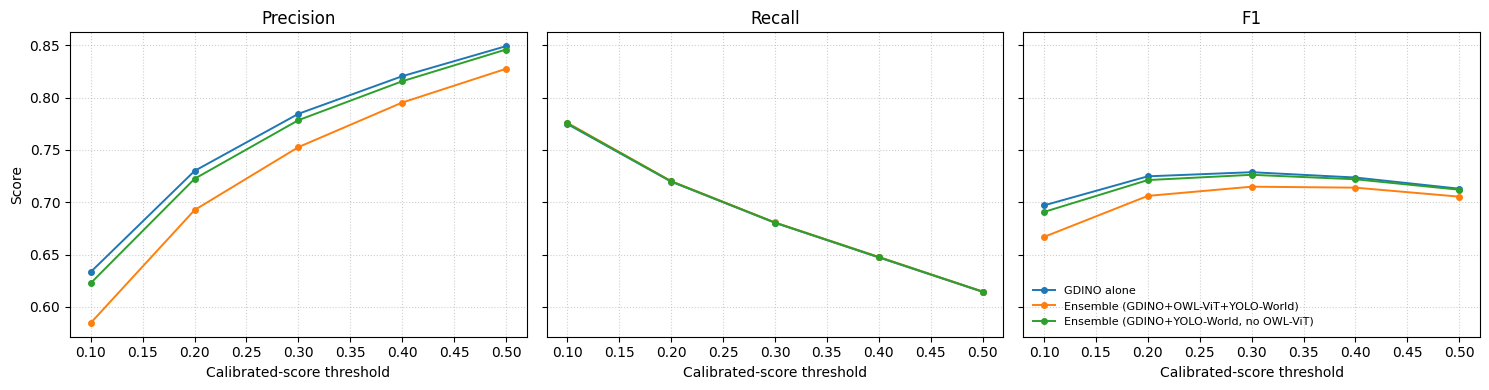

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    for name in OVOD_CONFIGS:
        sub = ovod_threshold_sweep[ovod_threshold_sweep["method"] == name].sort_values("threshold")
        ax.plot(sub["threshold"], sub[metric], marker="o", markersize=4, linewidth=1.4, label=name)
    ax.set_xlabel("Calibrated-score threshold")
    ax.set_title(metric.capitalize())
    ax.grid(True, ls=":", alpha=0.6)
axes[0].set_ylabel("Score")
axes[-1].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig("plots/OVOD_ensemble_threshold_sweep.pdf", dpi=300, bbox_inches="tight")
plt.show()

**Reading the sweep**: Grounding DINO alone has the highest F1 at every threshold.
Adding YOLO-World costs little (F1 gap 0.006 at t=0.1, 0.001 at t=0.5), whereas the
3-model ensemble with OWL-ViT falls further behind as the threshold is lowered: its
F1 gap to GDINO alone grows from 0.008 at t=0.5 (0.7053 vs. 0.7129) to 0.030 at t=0.1
(0.6669 vs. 0.6970). Lower thresholds admit more of OWL-ViT's low-confidence false
positives, so additional detectors do not recover recall that Grounding DINO misses.

# 2 AP / AS Ablation: PLS vs. GKR vs. kNN, All Four Datasets

Best-achievable `AP` and `AS_strict` (reported as AS) at 1%, 10% and 100% budget for
the three parametrized models (PLS, GKR, kNN — as opposed to Baseline/Resort/Bayes),
across all four datasets. The best value per metric is derived independently via
`best_of` from each dataset's full grid-search results CSV (the same files
`annotation_benchmark_results.ipynb` uses), since `*_grid_search_best.csv` only
carries `best_AP`/`best_AS`.

In [7]:
GRID_CSVS = {
    "COCO":       "experiments/coco_val_baseline_comp_simple/grid_search/coco_val_baseline_comp_simple_grid_search_results.csv",
    "Cityscapes": "experiments/cityscapes_trainval_baseline_comp_simple/grid_search/cityscapes_trainval_baseline_comp_simple_grid_search_results.csv",
    "KITTI":      "experiments/kitti_train_baseline_comp_simple/grid_search/kitti_train_baseline_comp_simple_grid_search_results.csv",
    "Pascal VOC": "experiments/voc_trainval_baseline_comp_simple/grid_search/voc_trainval_baseline_comp_simple_grid_search_results.csv",
}
TARGET_BUDGETS   = [0.01, 0.10, 1.00]
ABLATION_METHODS = ["PLS", "GKR", "kNN"]
ABLATION_METRICS = ["AP", "AS_strict"]


def best_of(df, metric):
    return (df.sort_values(metric, ascending=False)
              .groupby(["method", "budget"], as_index=False).first()
              [["method", "budget", metric]])


ablation_rows = []
for dataset_name, csv_path in GRID_CSVS.items():
    full = pd.read_csv(csv_path)
    for metric in ABLATION_METRICS:
        best = best_of(full, metric)
        for method in ABLATION_METHODS:
            for budget in TARGET_BUDGETS:
                match = best[(best["method"] == method) & np.isclose(best["budget"], budget)]
                value = match[metric].iloc[0] if len(match) else np.nan
                ablation_rows.append(dict(Dataset=dataset_name, Budget=budget, Method=method,
                                           Metric=metric, Value=value))

ablation_long = pd.DataFrame(ablation_rows)
ablation_table = ablation_long.pivot_table(index=["Dataset", "Budget"], columns=["Method", "Metric"],
                                            values="Value", sort=False)
ablation_table = ablation_table.reindex(
    index=pd.MultiIndex.from_product([GRID_CSVS.keys(), TARGET_BUDGETS], names=["Dataset", "Budget"]),
    columns=pd.MultiIndex.from_product([ABLATION_METHODS, ABLATION_METRICS], names=["Method", "Metric"]),
)
ablation_table.round(4)

Method                PLS               GKR               kNN          
Metric                 AP AS_strict      AP AS_strict      AP AS_strict
Dataset    Budget                                                      
COCO       0.01    0.4602    0.2848  0.4850    0.2661  0.4786    0.2378
           0.10    0.4941    0.3517  0.4919    0.3527  0.4816    0.3081
           1.00    0.5285    0.4061  0.5206    0.4165  0.4959    0.3600
Cityscapes 0.01    0.2858    0.3899  0.2998    0.3884  0.2821    0.3718
           0.10    0.3051    0.3941  0.3026    0.3968  0.2948    0.3859
           1.00    0.3201    0.4127  0.3156    0.4112  0.3010    0.3937
KITTI      0.01    0.2827    0.4234  0.2968    0.4348  0.2851    0.4273
           0.10    0.3108    0.4377  0.3081    0.4440  0.2899    0.4348
           1.00    0.3312    0.4626  0.3215    0.4646  0.3038    0.4434
Pascal VOC 0.01    0.6864    0.5815  0.6946    0.5425  0.6897    0.4598
           0.10    0.6988    0.6141  0.6954    0.6121  0.6936    0.5646
           1.00    0.7167    0.6567  0.7098    0.6609  0.6959    0.6140

In [8]:
ablation_table.round(4).to_csv("experiments/ablation_as_ap_table.csv")
print("Saved -> experiments/ablation_as_ap_table.csv")

Saved -> experiments/ablation_as_ap_table.csv


# 3 CLIP-Embedding Graph vs. GDino-Embedding Graph

Builds PLS's k-NN similarity graph from 512-dim CLIP ViT-B/32 image-crop embeddings
(`inference/clip_embeddings.py`) instead of the default 256-dim GDino decoder
embeddings, on COCO val (the only dataset with a `clip_embedding` column).

Both embeddings are run with identical settings: fixed `k=10`, `alpha=0.9` (no grid
search), `bandwidth_scale=1.0`, `configs/FGMRES.json`, `only_objects=True`, and an
image-level budget (1%/10%/100% of images sampled without replacement, seed 42). The
GDino-vs-CLIP comparison is therefore controlled within this section, but absolute
numbers are not comparable to Section 2 or the main AP/AS table, which report the
best of a 150-combination grid over (`k`, `alpha`, `bandwidth_scale`) with a
detection-level budget.

The graph only depends on `(k, embedding)`, not on the budget, so for each budget the
supervision draw is passed via `label_spreading_object_conventional`'s `indices`
argument.

In [9]:
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

label_spreading_dir = os.path.join(repo_root, "label_spreading")
if label_spreading_dir not in sys.path:
    sys.path.insert(0, label_spreading_dir)

from src import label_spreading_object_conventional
from evaluation import evaluate_result

CLIP_DATASET_PATH = os.path.join(repo_root, "data/matched_dataset/coco_val_matched.parquet")
CLIP_SOFT_GT_PATH = os.path.join(repo_root, "data/soft_datasets/soft_COCO_2017_val.json")
CLIP_AMGX_CONFIG  = os.path.join(label_spreading_dir, "configs/FGMRES.json")
CLIP_SCORE_THR    = 0.2
CLIP_K, CLIP_ALPHA = 10, 0.9   # fixed, not grid-searched
CLIP_ONLY_OBJECTS  = True
CLIP_BUDGETS       = [0.01, 0.10, 1.00]
CLIP_EMBEDDINGS    = ["gdino_embedding", "clip_embedding"]

df_full_clip = pd.read_parquet(CLIP_DATASET_PATH)
dataset_clip_base = df_full_clip[df_full_clip["gdino_score"] >= CLIP_SCORE_THR].copy().reset_index(drop=True)
sl = np.array([v for v in dataset_clip_base["soft_label"].values])
dataset_clip_base["soft_label"] = list(sl)
dataset_clip_base["is_object"] = dataset_clip_base["gdino_match"].astype(float)

print(f"{len(dataset_clip_base):,} detections  |  "
      f"clip_embedding dim = {len(dataset_clip_base['clip_embedding'].iloc[0])}  |  "
      f"gdino_embedding dim = {len(dataset_clip_base['gdino_embedding'].iloc[0])}")

/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


85,991 detections  |  clip_embedding dim = 512  |  gdino_embedding dim = 256


In [10]:
image_ids_unique_clip = dataset_clip_base["image_id"].unique()

clip_rows = []
pdata_by_budget_embedding = {}   # (budget, embedding) -> pdata, reused by the Bayes-blend section below
indices_by_budget = {}           # budget -> indices_b, reused for the calibrator fit below
for budget in CLIP_BUDGETS:
    np.random.seed(42)
    n_sampled = max(1, int(len(image_ids_unique_clip) * budget))
    sampled_ids = np.random.choice(image_ids_unique_clip, size=n_sampled, replace=False)
    indices_b = np.where(dataset_clip_base["image_id"].isin(sampled_ids))[0]
    indices_by_budget[budget] = indices_b

    for embedding in CLIP_EMBEDDINGS:
        pdata = label_spreading_object_conventional(
            f"clip_ablation_b{budget}_{embedding}",
            only_objects      = CLIP_ONLY_OBJECTS,
            dataset            = dataset_clip_base.copy(),
            data_space         = embedding,
            label_column       = "label",
            prob_label_column  = "soft_label",
            score_column       = "is_object",
            n_data             = "all",
            k                  = CLIP_K,
            alpha              = CLIP_ALPHA,
            n_samples          = len(indices_b),
            indices            = indices_b,
            config             = CLIP_AMGX_CONFIG,
        )
        pdata_by_budget_embedding[(budget, embedding)] = pdata

        res = evaluate_result(pdata, compute_ap=True, compute_as=True,
                               soft_gt_path=CLIP_SOFT_GT_PATH, soft_label_thresh=0.5).iloc[0]
        clip_rows.append(dict(Budget=budget, Embedding=embedding,
                               AP=float(res["AP"]), AS_strict=float(res["AS_strict"])))
        print(f"budget={budget:5.0%}  embedding={embedding:16s}  "
              f"AP={res['AP']:.4f}  AS_strict={res['AS_strict']:.4f}")

clip_ablation_df = pd.DataFrame(clip_rows)
clip_ablation_table = clip_ablation_df.pivot(index="Budget", columns="Embedding", values=["AP", "AS_strict"])
clip_ablation_table.round(4)

use pre-defined indices


budget=   1%  embedding=gdino_embedding   AP=0.4436  AS_strict=0.2775
use pre-defined indices


budget=   1%  embedding=clip_embedding    AP=0.2941  AS_strict=0.1078
use pre-defined indices


budget=  10%  embedding=gdino_embedding   AP=0.4862  AS_strict=0.3178
use pre-defined indices


budget=  10%  embedding=clip_embedding    AP=0.3578  AS_strict=0.1713
use pre-defined indices


budget= 100%  embedding=gdino_embedding   AP=0.5271  AS_strict=0.3493
use pre-defined indices


budget= 100%  embedding=clip_embedding    AP=0.4992  AS_strict=0.2151


AP                      AS_strict                
Embedding clip_embedding gdino_embedding clip_embedding gdino_embedding
Budget                                                                 
0.01              0.2941          0.4436         0.1078          0.2775
0.10              0.3578          0.4862         0.1713          0.3178
1.00              0.4992          0.5271         0.2151          0.3493

In [11]:
clip_ablation_df.to_csv("experiments/ablation_clip_vs_gdino_graph.csv", index=False)
print("Saved -> experiments/ablation_clip_vs_gdino_graph.csv")

Saved -> experiments/ablation_clip_vs_gdino_graph.csv


## 3.1 Bayesian blend: does CLIP's graph add independent information?

CLIP and GDino embeddings come from unrelated models, so the neighbors each graph
finds for a given detection need not agree — CLIP's graph might catch a useful
neighbor GDino's graph misses (or vice versa), even though CLIP's graph is clearly
weaker *alone* (Section 3 above). This blends the two graphs' propagated objectness
as independent evidence in objectness space (rather than via `baseline_comparison.py`'s
class-posterior `build_bayes_dataset`):

```
unnorm_1 = kappa * prior + F_gdino_obj_1 + F_clip_obj_1
unnorm_0 = kappa * (1 - prior) + F_gdino_obj_0 + F_clip_obj_0
p_bayes  = unnorm_1 / (unnorm_0 + unnorm_1)
```

`prior` is a per-budget isotonic calibration of the raw GDino score against
`gdino_match`, fit only on that budget's supervision indices, with anchor points
(0,0) and (1,1) added so the fit spans the full score range. `F_<graph>_obj_1/0` is
that graph's PLS run: `p_pls * trials` / `(1-p_pls) * trials`. `kappa` is searched
over a grid per budget. Three variants are compared against each other and against
the two graphs run alone:
- **GDino-graph + prior** — GDino graph only.
- **CLIP-graph + prior** — CLIP graph only.
- **Combined (GDino-graph + CLIP-graph) + prior** — both graphs' evidence pooled; tests
  whether CLIP contributes information GDino's graph does not.

All variants reuse the GDino-graph PLS run's class-conditional `p_hat` (only the
objectness `score_est` is swapped before `p_hat_mod`/`prediction_mod` are rebuilt
via `_apply_object_conditioning`), which isolates the effect of the objectness blend
from differences in class predictions.

In [12]:
from sklearn.isotonic import IsotonicRegression
from src import _apply_object_conditioning

KAPPA_GRID_CLIP = [0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]


def build_bayes_objectness_dataset(template_ds, p_bayes, run_tag):
    """Wraps a blended objectness score back into an evaluate_result-ready dataset:
    keeps template_ds's own class-conditional p_hat unchanged, swaps in the blended
    score_est, and rebuilds p_hat_mod/prediction_mod via the same conditioning every
    spreading variant already uses."""
    ds = template_ds.copy()
    ds["score_est"] = list(np.stack([1.0 - p_bayes, p_bayes], axis=1))
    _apply_object_conditioning(ds)
    ds.attrs["run_meta"] = dict(template_ds.attrs["run_meta"], dataset_name=run_tag)
    return ds


bayes_rows = []
for budget in CLIP_BUDGETS:
    indices_b = indices_by_budget[budget]

    raw_score    = dataset_clip_base["gdino_score"].to_numpy()
    match_target = dataset_clip_base["gdino_match"].to_numpy()
    anchor_x = np.concatenate([[0.0, 1.0], raw_score[indices_b]])
    anchor_y = np.concatenate([[0.0, 1.0], match_target[indices_b]])
    ir_clip = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
    ir_clip.fit(anchor_x, anchor_y)
    prior_obj = ir_clip.predict(raw_score)

    pdata_gdino = pdata_by_budget_embedding[(budget, "gdino_embedding")]
    pdata_clip  = pdata_by_budget_embedding[(budget, "clip_embedding")]

    p_pls_gdino    = np.vstack(pdata_gdino["score_est"].to_numpy())[:, 1]
    trials_gdino   = pdata_gdino["trials"].to_numpy()
    F_gdino_obj_1  = p_pls_gdino * trials_gdino
    F_gdino_obj_0  = (1.0 - p_pls_gdino) * trials_gdino

    p_pls_clip     = np.vstack(pdata_clip["score_est"].to_numpy())[:, 1]
    trials_clip    = pdata_clip["trials"].to_numpy()
    F_clip_obj_1   = p_pls_clip * trials_clip
    F_clip_obj_0   = (1.0 - p_pls_clip) * trials_clip

    VARIANTS = {
        "GDino-graph + prior":            (F_gdino_obj_1,                  F_gdino_obj_0),
        "CLIP-graph + prior":             (F_clip_obj_1,                   F_clip_obj_0),
        "Combined (GDino+CLIP) + prior":  (F_gdino_obj_1 + F_clip_obj_1,   F_gdino_obj_0 + F_clip_obj_0),
    }

    for variant_name, (F_obj_1, F_obj_0) in VARIANTS.items():
        for kappa in KAPPA_GRID_CLIP:
            unnorm_1 = kappa * prior_obj + F_obj_1
            unnorm_0 = kappa * (1 - prior_obj) + F_obj_0
            p_bayes = unnorm_1 / (unnorm_0 + unnorm_1)

            ds = build_bayes_objectness_dataset(pdata_gdino, p_bayes, f"bayes_b{budget}_{variant_name}_k{kappa}")
            res = evaluate_result(ds, compute_ap=True, compute_as=True,
                                   soft_gt_path=CLIP_SOFT_GT_PATH, soft_label_thresh=0.5).iloc[0]
            bayes_rows.append(dict(Budget=budget, Variant=variant_name, kappa=kappa,
                                    AP=float(res["AP"]), AS_strict=float(res["AS_strict"])))
    print(f"budget={budget:.0%} done", flush=True)

bayes_results = pd.DataFrame(bayes_rows)
bayes_results.to_csv("experiments/ablation_clip_bayes_kappa_search.csv", index=False)

budget=1% done


budget=10% done


budget=100% done


In [13]:
def best_of_bayes(df, metric):
    return (df.sort_values(metric, ascending=False)
              .groupby(["Variant", "Budget"], as_index=False).first()
              [["Variant", "Budget", metric]]
              .rename(columns={metric: f"{metric}_best"}))


bayes_best = None
for metric in ["AP", "AS_strict"]:
    b = best_of_bayes(bayes_results, metric)
    bayes_best = b if bayes_best is None else bayes_best.merge(b, on=["Variant", "Budget"])

# Fold in the two graphs run alone (Section 3 above, no Bayes blend) as reference rows
alone_rows = clip_ablation_df.rename(columns={"AP": "AP_best", "AS_strict": "AS_strict_best"})
alone_rows["Variant"] = alone_rows["Embedding"].map({
    "gdino_embedding": "GDino-graph alone (no blend)",
    "clip_embedding":  "CLIP-graph alone (no blend)",
})
alone_rows = alone_rows[["Variant", "Budget", "AP_best", "AS_strict_best"]]

clip_bayes_comparison = pd.concat([alone_rows, bayes_best], ignore_index=True)
clip_bayes_comparison_table = clip_bayes_comparison.pivot(index="Budget", columns="Variant",
                                                            values=["AP_best", "AS_strict_best"])
clip_bayes_comparison_table.round(4)

AP_best                              \
Variant CLIP-graph + prior CLIP-graph alone (no blend)   
Budget                                                   
0.01                0.4931                      0.2941   
0.10                0.4987                      0.3578   
1.00                0.5254                      0.4992   

                                                           \
Variant Combined (GDino+CLIP) + prior GDino-graph + prior   
Budget                                                      
0.01                           0.4945              0.4932   
0.10                           0.5025              0.5028   
1.00                           0.5347              0.5271   

                                         AS_strict_best  \
Variant GDino-graph alone (no blend) CLIP-graph + prior   
Budget                                                    
0.01                          0.4436             0.2482   
0.10                          0.4862             0.2985   
1.00                          0.5271             0.3285   

                                                                   \
Variant CLIP-graph alone (no blend) Combined (GDino+CLIP) + prior   
Budget                                                              
0.01                         0.1078                        0.2564   
0.10                         0.1713                        0.3126   
1.00                         0.2151                        0.3472   

                                                          
Variant GDino-graph + prior GDino-graph alone (no blend)  
Budget                                                    
0.01                 0.2722                       0.2775  
0.10                 0.3202                       0.3178  
1.00                 0.3493                       0.3493

In [14]:
clip_bayes_comparison.to_csv("experiments/ablation_clip_bayes_comparison.csv", index=False)
print("Saved -> experiments/ablation_clip_bayes_comparison.csv")

Saved -> experiments/ablation_clip_bayes_comparison.csv


# 4 Summary tables for the paper: why Grounding DINO (alone, its own embeddings)

Two design choices — using Grounding DINO alone rather than an OVOD ensemble, and
building the PLS similarity graph on GDino's decoder embeddings rather than CLIP crop
embeddings — are backed by the ablations in Sections 1 and 3. This section distills
both into the table used in the paper's ablation discussion.

In [15]:
os.makedirs("tables", exist_ok=True)

# ── OVOD ensemble @ the operating threshold (0.5) used throughout this work ──
ovod_sweep = pd.read_csv("experiments/ablation_ovod_threshold_sweep.csv")
ovod_at_05 = ovod_sweep[np.isclose(ovod_sweep["threshold"], 0.5)].set_index("method")

OVOD_ROW_LABELS = {
    "GDINO alone": "Grounding DINO alone",
    "Ensemble (GDINO+YOLO-World, no OWL-ViT)": "+ YOLO-World",
    "Ensemble (GDINO+OWL-ViT+YOLO-World)": "+ YOLO-World + OWL-ViT",
}

ovod_rows_latex = []
for method, label in OVOD_ROW_LABELS.items():
    row = ovod_at_05.loc[method]
    ovod_rows_latex.append(
        f"{label} & {row['precision'] * 100:.1f} & {row['recall'] * 100:.1f} & {row['f1'] * 100:.1f} \\\\"
    )

ovod_subtable = "\n".join([
    r"\begin{subtable}[t]{0.34\linewidth}",
    r"\centering",
    r"\caption{OVOD ensemble (threshold $=0.5$)}",
    r"\label{tab:ovod_ensemble_ablation}",
    r"\resizebox{\linewidth}{!}{%",
    r"\setlength{\tabcolsep}{3pt}",
    r"\begin{tabular}{lrrr}",
    r"\toprule",
    r"Method & Prec. & Recall & F1 \\",
    r"\midrule",
    *ovod_rows_latex,
    r"\bottomrule",
    r"\end{tabular}",
    r"}",
    r"\end{subtable}",
])

# ── GDino-embedding graph vs. CLIP-embedding graph, alone and Bayesian-blended ──
clip_bayes = pd.read_csv("experiments/ablation_clip_bayes_comparison.csv")
clip_bayes["BudgetLabel"] = clip_bayes["Budget"].map(lambda b: f"{b * 100:g}\\%")

CLIP_VARIANT_ORDER = [
    "GDino-graph alone (no blend)",
    "CLIP-graph alone (no blend)",
    "CLIP-graph + prior",
    "GDino-graph + prior",
    "Combined (GDino+CLIP) + prior",
]
CLIP_VARIANT_LABELS = {
    "GDino-graph alone (no blend)": "GDino-graph alone",
    "CLIP-graph alone (no blend)": "CLIP-graph alone",
    "CLIP-graph + prior": "CLIP-graph + prior",
    "GDino-graph + prior": "GDino-graph + prior",
    "Combined (GDino+CLIP) + prior": "Combined (GDino+CLIP) + prior",
}
BUDGET_LABELS = ["1\\%", "10\\%", "100\\%"]

ap_piv = clip_bayes.pivot_table(index="Variant", columns="BudgetLabel", values="AP_best").reindex(
    index=CLIP_VARIANT_ORDER, columns=BUDGET_LABELS)
as_piv = clip_bayes.pivot_table(index="Variant", columns="BudgetLabel", values="AS_strict_best").reindex(
    index=CLIP_VARIANT_ORDER, columns=BUDGET_LABELS)

clip_rows_latex = []
for variant in CLIP_VARIANT_ORDER:
    ap_vals = [ap_piv.loc[variant, b] * 100 for b in BUDGET_LABELS]
    as_vals = [as_piv.loc[variant, b] * 100 for b in BUDGET_LABELS]
    vals = ap_vals + as_vals
    clip_rows_latex.append(f"{CLIP_VARIANT_LABELS[variant]} & " + " & ".join(f"{v:.1f}" for v in vals) + r" \\")

clip_subtable = "\n".join([
    r"\begin{subtable}[t]{0.62\linewidth}",
    r"\centering",
    r"\caption{GDino- vs.\ CLIP-embedding graph}",
    r"\label{tab:clip_graph_ablation}",
    r"\resizebox{\linewidth}{!}{%",
    r"\setlength{\tabcolsep}{3pt}",
    r"\begin{tabular}{l|rrr|rrr}",
    r"\toprule",
    r" & \multicolumn{3}{c}{AP} & \multicolumn{3}{c}{AS} \\",
    r"Variant & 1\% & 10\% & 100\% & 1\% & 10\% & 100\% \\",
    r"\midrule",
    *clip_rows_latex,
    r"\bottomrule",
    r"\end{tabular}",
    r"}",
    r"\end{subtable}",
])

# needs \usepackage{booktabs}, \usepackage{subcaption}, \usepackage{graphicx} in the LaTeX doc
combined_table = "\n".join([
    r"\begin{table*}[t]",
    r"\centering",
    r"\caption{Ablation: Grounding DINO ensembling (left) and embedding-graph choice (right). "
    r"Recall is essentially identical across all OVOD ensemble configurations -- additional "
    r"detectors add false positives, not recall. AS is the strict (AS\_strict) definition used "
    r"throughout this paper.}",
    r"\label{tab:ablation_ovod_clip}",
    ovod_subtable,
    r"\hfill",
    clip_subtable,
    r"\end{table*}",
])

print(combined_table)
with open("tables/ablation_ovod_clip.tex", "w") as f:
    f.write(combined_table + "\n")
print("\nSaved -> analysis/tables/ablation_ovod_clip.tex")

\begin{table*}[t]
\centering
\caption{Ablation: Grounding DINO ensembling (left) and embedding-graph choice (right). Recall is essentially identical across all OVOD ensemble configurations -- additional detectors add false positives, not recall. AS is the strict (AS\_strict) definition used throughout this paper.}
\label{tab:ablation_ovod_clip}
\begin{subtable}[t]{0.34\linewidth}
\centering
\caption{OVOD ensemble (threshold $=0.5$)}
\label{tab:ovod_ensemble_ablation}
\resizebox{\linewidth}{!}{%
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lrrr}
\toprule
Method & Prec. & Recall & F1 \\
\midrule
Grounding DINO alone & 84.9 & 61.4 & 71.3 \\
+ YOLO-World & 84.6 & 61.5 & 71.2 \\
+ YOLO-World + OWL-ViT & 82.7 & 61.5 & 70.5 \\
\bottomrule
\end{tabular}
}
\end{subtable}
\hfill
\begin{subtable}[t]{0.62\linewidth}
\centering
\caption{GDino- vs.\ CLIP-embedding graph}
\label{tab:clip_graph_ablation}
\resizebox{\linewidth}{!}{%
\setlength{\tabcolsep}{3pt}
\begin{tabular}{l|rrr|rrr}
\toprule
 & \mul